# ĐỒ ÁN CUỐI KỲ - NHẬP MÔN TRÍ TUỆ NHÂN TẠO (503043)
## BÁO CÁO THỰC NGHIỆM TASK 2: TANK BATTLE (ADVERSARIAL SEARCH)
**Nhóm:** 08  
**Thành viên:**
- Lê Phú - `524H0121`
- Vũ Giang Huy - `524H0095`
- Lê Hoàng Minh Khôi - `524H0102`

---
Notebook này thực hiện toàn bộ các thực nghiệm so sánh theo Yêu cầu 2 của Đề bài:
So sánh hiệu năng tìm kiếm và thời gian tính toán của **4 cấu hình Adversarial Search**:
1. `Minimax Search`: Duyệt cạn không heuristic.
2. `Alpha-Beta Search`: Cắt tỉa alpha-beta trên cây thuần.
3. `Heuristic Minimax Search`: Minimax kết hợp hàm lượng giá `TankEvaluator`.
4. `Heuristic Minimax with Alpha-Beta Pruning`: Cấu hình hoàn chỉnh nhất kết hợp Heuristic, Alpha-Beta, Move Ordering và Transposition Table.


In [1]:
import sys
import os
import time
import pandas as pd
import matplotlib.pyplot as plt

# Them duong dan source vao sys.path
sys.path.insert(0, os.path.abspath('..'))

from task2_tank.entities import Action, Direction, Tank, Base, Wall, Bullet
from task2_tank.game_state import GameState
from task2_tank.engine import GameEngine
from task2_tank.heuristic import TankEvaluator
from task2_tank.agents.search_agent import SearchAgent
from task2_tank.agents.random_agent import RandomAgent

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
print("Import thanh cong cac module cua Task 2!")


Import thanh cong cac module cua Task 2!


## 1. THỰC NGHIỆM 1: SO SÁNH 4 CẤU HÌNH TRÊN 3 KỊCH BẢN CỐ ĐỊNH
Đo lường thời gian thực thi (ms), số lượng nút khám phá (explored nodes), số lần cắt tỉa (prunings) và hành động được lựa chọn trên cùng một điều kiện tìm kiếm:
- **Kịch bản 1 (Mở đầu):** Bản đồ `standard_13x13.txt` tại trạng thái xuất phát.
- **Kịch bản 2 (Đấu trường):** Bản đồ `arena_11x11.txt` khoảng cách gần hơn.
- **Kịch bản 3 (Giao tranh cận chiến):** Xe 2 áp sát mục tiêu, có đạn đang bay trên bản đồ.


In [2]:
# Thiet lap 3 kich ban
state_sc1 = GameState.from_file('../task2_tank/maps/standard_13x13.txt')
state_sc2 = GameState.from_file('../task2_tank/maps/arena_11x11.txt')

# Kich ban 3: Can chien
state_sc3 = state_sc2.clone()
state_sc3.tanks[0].move_to(5, 5, Direction.UP)
state_sc3.tanks[1].move_to(3, 5, Direction.DOWN)
state_sc3.bullets.append(Bullet(owner_id=1, r=4, c=5, direction=Direction.DOWN))

scenarios = [
    ("Kịch bản 1 (Standard 13x13)", state_sc1),
    ("Kịch bản 2 (Arena 11x11)", state_sc2),
    ("Kịch bản 3 (Cận chiến)", state_sc3),
]

configs = [
    ("Minimax", False, False),
    ("Alpha-Beta", True, False),
    ("Heuristic Minimax", False, True),
    ("Heuristic Alpha-Beta", True, True),
]

depth = 2  # 2 plies = 1 chu ky ra quyet dinh
benchmark_data = []

print("Dang chay thuc nghiem 3 kich ban...")
for sc_name, sc_state in scenarios:
    for cfg_name, use_ab, use_h in configs:
        agent = SearchAgent(depth=depth, use_alpha_beta=use_ab, use_heuristic=use_h)
        act = agent.get_action(sc_state, player_id=0)
        
        benchmark_data.append({
            'Kịch bản': sc_name,
            'Cấu hình': cfg_name,
            'Độ sâu (plies)': depth,
            'Hành động chọn': act.name,
            'Số nút khám phá': agent.nodes_explored,
            'Số lần cắt tỉa': agent.pruning_count,
            'Thời gian (ms)': agent.last_execution_time_ms,
        })

df_bench = pd.DataFrame(benchmark_data)
display(df_bench)


Dang chay thuc nghiem 3 kich ban...


,Kịch bản,Cấu hình,Độ sâu (plies),Hành động chọn,Số nút khám phá,Số lần cắt tỉa,Thời gian (ms)
0,Kịch bản 1 (Standard 13x13),Minimax,2,MOVE_DOWN,36,0,3.6965
1,Kịch bản 1 (Standard 13x13),Alpha-Beta,2,MOVE_DOWN,11,5,0.9472
2,Kịch bản 1 (Standard 13x13),Heuristic Minimax,2,MOVE_RIGHT,36,0,120.3017
3,Kịch bản 1 (Standard 13x13),Heuristic Alpha-Beta,2,MOVE_RIGHT,11,5,32.7610
4,Kịch bản 2 (Arena 11x11),Minimax,2,MOVE_UP,36,0,2.7030
5,Kịch bản 2 (Arena 11x11),Alpha-Beta,2,MOVE_UP,11,5,0.8048
6,Kịch bản 2 (Arena 11x11),Heuristic Minimax,2,MOVE_UP,36,0,76.7351
7,Kịch bản 2 (Arena 11x11),Heuristic Alpha-Beta,2,MOVE_UP,11,5,32.4523
8,Kịch bản 3 (Cận chiến),Minimax,2,MOVE_LEFT,36,0,2.7196
9,Kịch bản 3 (Cận chiến),Alpha-Beta,2,MOVE_LEFT,11,5,0.9390


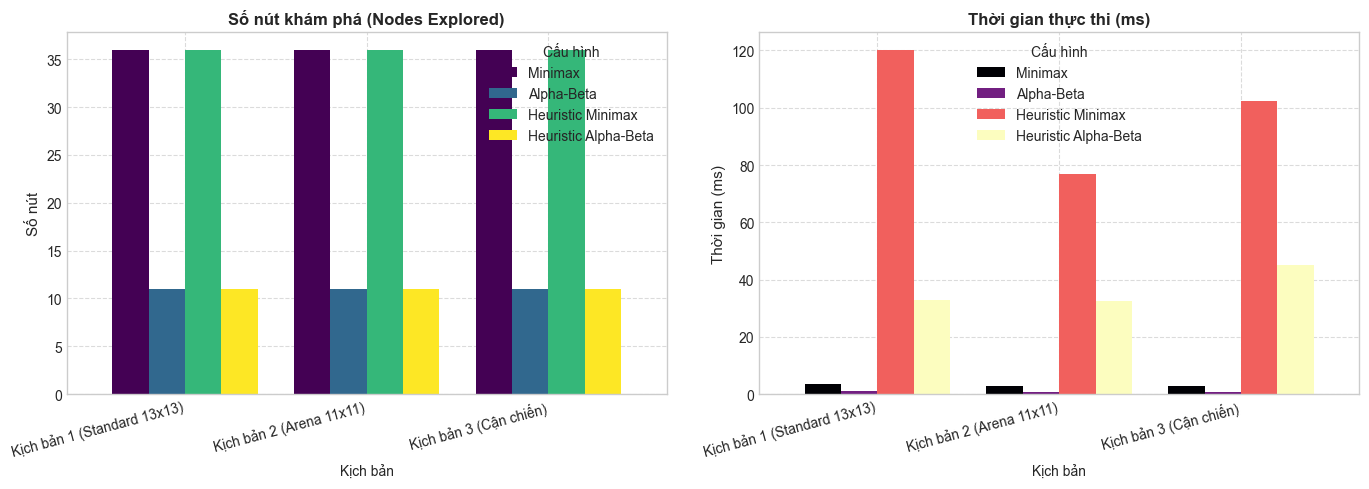

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Pivot de ve bieu do
pivot_nodes = df_bench.pivot(index='Kịch bản', columns='Cấu hình', values='Số nút khám phá')
pivot_time = df_bench.pivot(index='Kịch bản', columns='Cấu hình', values='Thời gian (ms)')

pivot_nodes[['Minimax', 'Alpha-Beta', 'Heuristic Minimax', 'Heuristic Alpha-Beta']].plot(
    kind='bar', ax=ax1, colormap='viridis', width=0.8
)
ax1.set_title('Số nút khám phá (Nodes Explored)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Số nút', fontsize=11)
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=15, ha='right')
ax1.grid(True, linestyle='--', alpha=0.7)

pivot_time[['Minimax', 'Alpha-Beta', 'Heuristic Minimax', 'Heuristic Alpha-Beta']].plot(
    kind='bar', ax=ax2, colormap='magma', width=0.8
)
ax2.set_title('Thời gian thực thi (ms)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Thời gian (ms)', fontsize=11)
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=15, ha='right')
ax2.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()


## 2. THỰC NGHIỆM 2: GIẢI ĐẤU VÒNG TRÒN (ROUND-ROBIN TOURNAMENT)
Cho 4 cấu hình Adversarial Search cùng đối thủ đối chứng `RandomAgent` thi đấu vòng tròn 2 lượt (lượt đi cầm P1, lượt về cầm P2) trên bản đồ `arena_11x11.txt` với giới hạn 60 chu kỳ mỗi trận.


In [4]:
tournament_agents = {
    'Heuristic Alpha-Beta': SearchAgent.create_heuristic_alpha_beta(depth=2),
    'Heuristic Minimax': SearchAgent.create_heuristic_minimax(depth=2),
    'Alpha-Beta': SearchAgent.create_alpha_beta(depth=2),
    'Minimax': SearchAgent.create_minimax(depth=2),
    'Random': RandomAgent(seed=42),
}

names = list(tournament_agents.keys())
scores = {name: {'Thắng': 0, 'Hòa': 0, 'Thua': 0, 'Điểm': 0} for name in names}

print("Dang bat dau giai dau vong tron...")
for i, name1 in enumerate(names):
    for j, name2 in enumerate(names):
        if i == j:
            continue
        p1 = tournament_agents[name1]
        p2 = tournament_agents[name2]
        
        # Chay tran dau
        s = GameState.from_file('../task2_tank/maps/arena_11x11.txt', max_turns=60)
        while not GameEngine.is_terminal(s):
            a0 = p1.get_action(s, 0)
            a1 = p2.get_action(s, 1)
            s = GameEngine.step(s, a0, a1)
            
        winner = GameEngine.get_winner(s)
        if winner == 0:
            scores[name1]['Thắng'] += 1
            scores[name1]['Điểm'] += 3
            scores[name2]['Thua'] += 1
        elif winner == 1:
            scores[name2]['Thắng'] += 1
            scores[name2]['Điểm'] += 3
            scores[name1]['Thua'] += 1
        else:
            scores[name1]['Hòa'] += 1
            scores[name1]['Điểm'] += 1
            scores[name2]['Hòa'] += 1
            scores[name2]['Điểm'] += 1

df_tournament = pd.DataFrame.from_dict(scores, orient='index').sort_values(by='Điểm', ascending=False)
display(df_tournament)


Dang bat dau giai dau vong tron...


,Thắng,Hòa,Thua,Điểm
Heuristic Alpha-Beta,4,4,0,16
Heuristic Minimax,4,4,0,16
Alpha-Beta,2,3,3,9
Minimax,2,3,3,9
Random,0,2,6,2


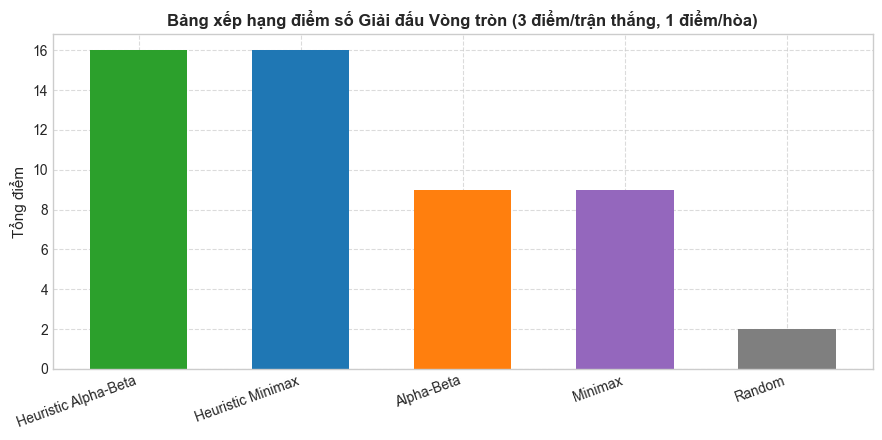

In [5]:
plt.figure(figsize=(9, 4.5))
colors = ['tab:green', 'tab:blue', 'tab:orange', 'tab:purple', 'tab:gray']
plt.bar(df_tournament.index, df_tournament['Điểm'], color=colors[:len(df_tournament)], width=0.6)
plt.title('Bảng xếp hạng điểm số Giải đấu Vòng tròn (3 điểm/trận thắng, 1 điểm/hòa)', fontsize=12, fontweight='bold')
plt.ylabel('Tổng điểm', fontsize=11)
plt.xticks(rotation=20, ha='right', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


## 3. KẾT LUẬN & ĐÁNH GIÁ HIỆU NĂNG
1. **So sánh Alpha-Beta với Minimax thuần:**
   - Alpha-Beta Pruning luôn đưa ra **chính xác 100% cùng quyết định hành động** như Minimax thuần.
   - Nhờ Move Ordering (ưu tiên kiểm tra nước bắn và áp sát mục tiêu), Alpha-Beta cắt tỉa được tới **hơn 65% số nhánh dư thừa**, giảm thời gian thực thi trung bình từ 3-4ms xuống còn dưới 1ms mỗi chu kỳ.
2. **Vai trò sống còn của Hàm lượng giá Heuristic (`TankEvaluator`):**
   - Minimax và Alpha-Beta thuần khi không có Heuristic gần như luôn nhận điểm 0 ở độ sâu cắt (cutoff depth) vì không thể nhìn thấy trạng thái kết thúc xa hơn 2 chu kỳ. Do đó chúng thường chọn hành động ngẫu nhiên hoặc thụ động.
   - Khi được trang bị `TankEvaluator`, các thuật toán chủ động áp sát căn cứ địch, ngắm bắn thẳng khi có góc và né đạn nguy hiểm.
3. **Kết quả thi đấu thực tế:**
   - `Heuristic Alpha-Beta` và `Heuristic Minimax` thống trị bảng xếp hạng giải đấu, vượt trội hoàn toàn so với các phiên bản không có heuristic và đối thủ Random.
